# STATS 201 Week 4 · Causal machine learning

**Learning goal.** Take a causal question from a treatment and an outcome through identification, estimation, and a robustness check. Explain which parts of your answer come from evidence and which depend on assumptions.

[Open the Week 4 lab in Colab](https://colab.research.google.com/github/sunshineluyao/ml4ss/blob/main/modules/05-causal-inference/week04_causal_ml.ipynb). Choose **Runtime → Run all**. Use **File → Save a copy in Drive** to keep your changes. A standard CPU runtime is sufficient. The results and figures below show a saved run with the original settings.

| Route | Work through | Change one thing |
| --- | --- | --- |
| **A · Economist** | Rebuild FTE employment from the Card–Krueger survey. Identify the policy contrast, interpret the before/after figure and test sensitivity. | Set `TREND_BIAS` to 1.5 in the separate robot workcell stress test. |
| **B · Computer scientist** | Inspect the simulator's true model. Discover compatible graphs, identify a dose effect under each, and estimate the effect with uncertainty. | Set `TIMING` to `"ordered"` and examine what a timing record adds. |

**Starting check.** A prediction model can use observed outcomes as target labels for held-out evaluation. An individual causal contrast involves potential outcomes under different actions for the same unit. In observed data, the alternative outcome is usually missing. A causal hypothesis therefore needs a credible design or model. The earlier robot classifier and the prediction MAE below answer prediction questions.

The historical survey and the two synthetic exercises answer different questions. Compare their identification reasoning before comparing their numbers.

In [1]:
import itertools
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Change ONE setting, then rerun all cells. Keep the seed for comparison.
SEED = 201
TRUE_EFFECT = 3.0
TREND_BIAS = 0.0       # Economist: try 1.5
TIMING = "baseline"    # Computer scientist: try "ordered"
HIDDEN_STRENGTH = 0.0  # Optional after locking TIMING to "ordered": try 0.9

if TIMING not in {"baseline", "ordered"}:
    raise ValueError('Set TIMING to "baseline" or "ordered".')

# The survey is available from public sources. For an offline class, set this to False
# and use the saved survey table and figure. The simulations run either way.
RUN_SURVEY_CASE = True
SURVEY_CSV_PATH = ""   # Optional verified copy of the pinned survey CSV

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.labelcolor": "#172B3A"
})

# A · Economist route

## A1 · Question, treatment, and economic hypothesis

**Guiding question.** What happened to fast-food staffing after New Jersey raised its minimum wage, relative to the staffing change we would expect without the increase?

The [2021 Prize in Economic Sciences](https://www.nobelprize.org/uploads/2021/10/press-economicsciencesprize2021-2.pdf) recognized David Card's empirical contributions to labor economics and Joshua Angrist and Guido Imbens's work on causal relationships. [Card and Krueger (1994)](https://eml.berkeley.edu/~card/papers/njmin-aer.pdf) compared fast-food restaurants in New Jersey and eastern Pennsylvania. On April 1, 1992, the minimum wage rose from **$4.25 to $5.05 per hour** in New Jersey and stayed **$4.25** in Pennsylvania.

| Design element | Definition in this case |
| --- | --- |
| Unit | A sampled restaurant from one of four chains, observed in two survey waves |
| Treatment | Exposure to the New Jersey minimum-wage increase after April 1. Actual pay and compliance can vary. |
| Outcome | Full-time-equivalent (FTE) employment per restaurant, counting full-time workers including managers plus half of part-time workers |
| Target effect | Mean FTE with the policy minus mean FTE under the no-increase counterfactual at follow-up for exposed New Jersey restaurants |
| Comparison and controls | Pennsylvania supplies the comparison trend. Differencing accounts for time-invariant restaurant characteristics and a common period shift. We also check sensitivity to pre-policy chain and company ownership. |
| Variables measured after treatment | Follow-up wage and hours may respond to the policy. Keep them out of the main adjustment for the total policy effect. |

**Why could employment change?** A binding wage floor changes the cost or availability of labor. Under competitive labor demand, a higher wage can reduce staffing when other inputs and product demand are fixed. With employer wage-setting power and upward-sloping labor supply, a moderate floor can reduce the gap between wages and marginal hiring cost and may increase hiring. Restaurants can also adjust hours, prices, or staffing composition. These mechanisms motivate the two-sided hypothesis $H_0:\tau_{\mathrm{ATT}}=0$ versus $H_1:\tau_{\mathrm{ATT}}\ne0$. The sign and magnitude remain empirical questions.

### Two 2026 readings

1. [Baker, Callaway, Cunningham, Goodman-Bacon & Sant'Anna, *Difference-in-Differences Designs: A Practitioner's Guide*](https://doi.org/10.1257/jel.20251650). Use the guide to examine who was exposed, which groups supply a comparison trend, and when a pretreatment check is possible.
2. [Wiltshire, McPherson, Reich & Sosinskiy, *Minimum Wage Effects and Monopsony Explanations*](https://doi.org/10.1086/735551). Use its analysis of minimum wages and employer market power to ask what data would distinguish mechanisms. The classroom analysis estimates a policy contrast. A mechanism test would need additional evidence.

## A2 · Source data and outcome construction

**Guiding question.** What enters the estimate and which restaurants are lost when we require two observed outcomes?

The [authors' public survey archive](https://davidcard.berkeley.edu/data_sets/njmin.zip) covers 410 restaurants (331 New Jersey, 79 eastern Pennsylvania). Wave 1 was in February–March 1992. Wave 2 began in November, with follow-up into December. Each source row contains before and after fields. The code tries the authors' public.dat first and can load a [pinned raw-field CSV copy](https://github.com/isaG001/card-krueger-replication/blob/cd9f1a0f7b04ae5386d7da1c89f5bd31116e430e/card_krueger_1994.csv) if needed. The saved run uses that pinned copy. FTE is recomputed from the component fields, and missing components remain missing.

| Source fields | How they enter |
| --- | --- |
| `state`, `chain`, `co_owned` | New Jersey indicator, chain, and whether the outlet is company-owned |
| `empft`, `nmgrs`, `emppt` and corresponding `…2` fields | Full-time, manager and part-time worker counts for wave 1 and wave 2 |
| `wage_st`, `wage_st2` | Starting wage in dollars per hour. Its change is context for policy exposure. |
| `status2` | Follow-up status. Examine closure and nonresponse when appraising the paired sample. |

Use two observed outcomes per restaurant for the main contrast, preserving recorded zero employment. The code never imputes a missing employment component as zero. Some paper tables use a different missingness and closure rule.

In [2]:
import hashlib
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile, BadZipFile

CK_ARCHIVE = "https://davidcard.berkeley.edu/data_sets/njmin.zip"
CK_CSV = ("https://raw.githubusercontent.com/isaG001/card-krueger-replication/"
          "cd9f1a0f7b04ae5386d7da1c89f5bd31116e430e/card_krueger_1994.csv")
CK_CSV_SHA256 = "bfd49ba946a3d6ff7afbdda10a5239b8f345278837ef574067d8ad545652022e"
SURVEY_FIELDS = '''
sheet chain co_owned state southj centralj northj pa1 pa2 shore ncalls
empft emppt nmgrs wage_st inctime firstinc bonus pctaff meals open hrsopen
psoda pfry pentree nregs nregs11 type2 status2 date2 ncalls2 empft2 emppt2
nmgrs2 wage_st2 inctime2 firstin2 special2 meals2 open2r hrsopen2 psoda2
pfry2 pentree2 nregs2 nregs112
'''.split()


def read_public_dat(binary_archive):
    with ZipFile(BytesIO(binary_archive)) as archive:
        public = next(name for name in archive.namelist()
                      if Path(name).name.lower() == "public.dat")
        return pd.read_csv(BytesIO(archive.read(public)), sep=r"\s+", header=None,
                           names=SURVEY_FIELDS, na_values=".")


def read_pinned_csv(binary_csv):
    if hashlib.sha256(binary_csv).hexdigest() != CK_CSV_SHA256:
        raise ValueError("The pinned raw-field CSV hash does not match.")
    return pd.read_csv(BytesIO(binary_csv))


def read_survey():
    if SURVEY_CSV_PATH:
        return read_pinned_csv(Path(SURVEY_CSV_PATH).read_bytes()), "Pinned raw-field survey CSV (local copy)"
    try:
        with urlopen(CK_ARCHIVE, timeout=12) as response:
            return read_public_dat(response.read()), "Card's public survey archive (public.dat)"
    except (OSError, BadZipFile, StopIteration, ValueError) as err:
        print(f"Author archive unavailable ({type(err).__name__}); trying the pinned CSV.")
    try:
        with urlopen(CK_CSV, timeout=12) as response:
            return read_pinned_csv(response.read()), "Pinned raw-field survey CSV"
    except (OSError, ValueError) as err:
        print(f"Survey download unavailable ({type(err).__name__}). Use the saved output or continue with the robot simulation.")
        return None, None


def make_fte(rows, part_weight=0.5):
    data = rows.copy()
    data["before"] = data.empft + data.nmgrs + part_weight * data.emppt
    data["after"] = data.empft2 + data.nmgrs2 + part_weight * data.emppt2
    data["change"] = data.after - data.before
    return data


survey, survey_source = read_survey() if RUN_SURVEY_CASE else (None, None)
if survey is not None:
    assert len(survey) == 410 and survey.state.value_counts().to_dict() == {1: 331, 0: 79}
    survey = make_fte(survey)
    counts = survey.groupby("state").agg(
        restaurants=("state", "size"), before_observed=("before", "count"),
        after_observed=("after", "count"), paired=("change", "count"),
        starting_wage_before=("wage_st", "mean"), starting_wage_after=("wage_st2", "mean")
    ).rename(index={0: "PA", 1: "NJ"})
    print(f"Data source: {survey_source}")
    print("Coverage and starting wages ($/hour):")
    print(counts.round(2).to_string())

Data source: Pinned raw-field survey CSV (local copy)
Coverage and starting wages ($/hour):
       restaurants  before_observed  after_observed  paired  starting_wage_before  starting_wage_after
state                                                                                                 
PA              79               77              77      75                  4.63                 4.62
NJ             331              321             319     309                  4.61                 5.08


## A3 · Identify and estimate the policy effect

**Guiding question.** When can Pennsylvania's change stand in for New Jersey's missing counterfactual?

Write $Y_{i1}(1)$ and $Y_{i1}(0)$ for the follow-up outcome with and without the increase. The target is $\tau_{\mathrm{ATT}}=E[Y_{i1}(1)-Y_{i1}(0)\mid G_i=1]$, where $G_i=1$ marks New Jersey. With no anticipation and **parallel untreated trends**, the groups would share the same mean change without the policy:

$$E[Y_{i1}(0)-Y_{i0}(0)\mid G_i=1]=E[Y_{i1}(0)-Y_{i0}(0)\mid G_i=0].$$

$$\widehat{\tau}_{\rm DiD}=(\bar Y_{\rm NJ,post}-\bar Y_{\rm NJ,pre})
 -(\bar Y_{\rm PA,post}-\bar Y_{\rm PA,pre}).$$

In a two-period regression on New Jersey, post, and their interaction, the interaction is the DiD for the same paired sample. For the adjusted sensitivity, regress the change on New Jersey, chain and company ownership, $\Delta Y_i=\alpha+\tau G_i+\gamma^\top X_i+e_i$. A causal interpretation requires credible parallel trends given those covariates, overlap, and a suitable model. Also consider spillovers, differential survey response, and other events that could have affected one state's staffing.

**Pseudocode**

1. Recode both outcomes in FTE. Keep restaurants with both observed.
2. Average the store-level changes separately by state.
3. Subtract the Pennsylvania change from the New Jersey change.
4. Add the Pennsylvania change to New Jersey's baseline to draw its implied no-policy trajectory. Recompute under alternative definitions and sample restrictions.

**Python.** `pandas` reads and groups the data, `scikit-learn` fits the adjustment sensitivity, and `Matplotlib` draws the comparison. `SciPy` computes the interval in the synthetic panel below. [statsmodels](https://www.statsmodels.org/stable/) and [PyFixest](https://pyfixest.org/) support regression and richer DiD workflows for designs with suitable independent assignment units.

Paired means and changes (FTE per restaurant):
       before  after  change
state                       
PA      23.38   21.1   -2.28
NJ      20.43   20.9    0.47

DiD: +2.75 FTE per restaurant. NJ no-policy comparison: 18.15 FTE.
Scale reference: 13.5% of NJ's paired baseline mean.


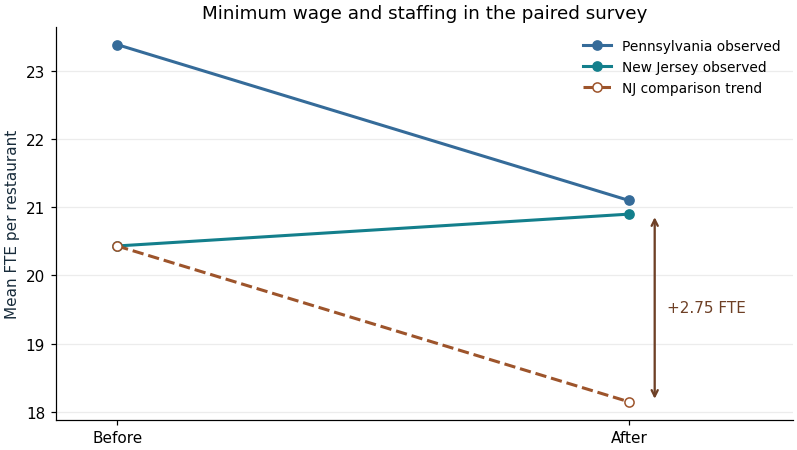

In [3]:
def paired_contrast(frame):
    paired = frame.dropna(subset=["change"])
    means = paired.groupby("state")[["before", "after", "change"]].mean()
    effect = means.loc[1, "change"] - means.loc[0, "change"]
    return effect, means, paired


if survey is not None:
    ck_did, ck_means, ck_pairs = paired_contrast(survey)
    nj_pre = ck_means.loc[1, "before"]
    nj_after = ck_means.loc[1, "after"]
    nj_counterfactual = nj_pre + ck_means.loc[0, "change"]
    print("Paired means and changes (FTE per restaurant):")
    print(ck_means.rename(index={0: "PA", 1: "NJ"}).round(2).to_string())
    print(f"\nDiD: {ck_did:+.2f} FTE per restaurant. NJ no-policy comparison: {nj_counterfactual:.2f} FTE.")
    print(f"Scale reference: {100 * ck_did / nj_pre:.1f}% of NJ's paired baseline mean.")

    fig, ax = plt.subplots(figsize=(7.25, 4.1), layout="constrained")
    for state, name, color in [(0, "Pennsylvania observed", "#356B99"),
                               (1, "New Jersey observed", "#137F8C")]:
        ax.plot([0, 1], ck_means.loc[state, ["before", "after"]],
                marker="o", lw=2, color=color, label=name)
    ax.plot([0, 1], [nj_pre, nj_counterfactual], "--", lw=2, color="#9D542B",
            marker="o", markerfacecolor="white", label="NJ comparison trend")
    ax.annotate("", xy=(1.05, nj_after), xytext=(1.05, nj_counterfactual),
                arrowprops={"arrowstyle": "<->", "color": "#6E4026", "lw": 1.5})
    ax.annotate(f"{ck_did:+.2f} FTE", xy=(1.05, (nj_after + nj_counterfactual) / 2),
                xytext=(8, 0), textcoords="offset points", va="center", color="#6E4026")
    ax.set(xlim=(-0.12, 1.32), xticks=[0, 1], xticklabels=["Before", "After"],
           ylabel="Mean FTE per restaurant", title="Minimum wage and staffing in the paired survey")
    ax.grid(axis="y", alpha=.24)
    ax.legend(loc="best", frameon=False, fontsize=9)
    plt.show()

## A4 · Interpret the plot and check robustness

**Guiding question.** Does the contrast reflect staffing growth in New Jersey, a fall in Pennsylvania, or both?

Read the two observed lines. The dashed line starts at New Jersey's observed baseline and applies Pennsylvania's observed change. The vertical gap to New Jersey's follow-up is the estimated DiD. Report the four means, both changes, the contrast and the paired sample sizes. In the saved run, New Jersey gains 0.47 FTE and Pennsylvania loses 2.28. Their difference is +2.75 FTE per restaurant, matching the paired contrast in Table 3. Most of the contrast comes from Pennsylvania's decline. Relative to New Jersey's 20.43 baseline FTE, the scale is about 13.5%. This is a baseline-scaled comparison, while observed staffing growth in New Jersey is 0.47 FTE.

**Statistical uncertainty.** Exposure varied at the state level, with one treated and one comparison state. Hundreds of stores do not create hundreds of independent policy assignments. Therefore, this class analysis reports the observed contrast and sensitivity estimates. The simulation below demonstrates how to interpret an interval when the workcells are independent by construction.

**Check sensitivity.** Recompute using all available wave means, change the part-time weight, remove one chain at a time, and condition on pre-policy chain and company ownership. These checks probe different sample and measurement decisions.

In [4]:
if survey is not None:
    checks = [("Paired sample", ck_did)]
    available = survey.groupby("state")[["before", "after"]].mean()
    checks.append(("Available waves (composition can change)",
                   (available.loc[1, "after"] - available.loc[1, "before"])
                   - (available.loc[0, "after"] - available.loc[0, "before"])))
    for weight in (0.25, 0.75):
        estimate, _, _ = paired_contrast(make_fte(survey, weight))
        checks.append((f"Part-time weight = {weight:.2f}", estimate))
    for number, name in {1: "Burger King", 2: "KFC", 3: "Roy Rogers", 4: "Wendy's"}.items():
        estimate, _, _ = paired_contrast(survey[survey.chain != number])
        checks.append((f"Leave out {name}", estimate))

    controls = pd.get_dummies(ck_pairs[["state", "chain", "co_owned"]].astype({"chain": "category"}),
                             columns=["chain"], drop_first=True, dtype=float)
    adjusted = LinearRegression().fit(controls, ck_pairs.change)
    checks.append(("Adjust for baseline chain and company ownership", adjusted.coef_[0]))
    print("Sensitivity estimates in FTE units (the part-time weight alters the measurement scale)")
    print(pd.DataFrame(checks, columns=["Comparison", "DiD or adjusted contrast"]).round(2).to_string(index=False))

Sensitivity estimates in FTE units (the part-time weight alters the measurement scale)
                                     Comparison  DiD or adjusted contrast
                                  Paired sample                      2.75
       Available waves (composition can change)                      2.75
                        Part-time weight = 0.25                      2.92
                        Part-time weight = 0.75                      2.58
                          Leave out Burger King                      1.55
                                  Leave out KFC                      3.56
                           Leave out Roy Rogers                      2.90
                              Leave out Wendy's                      2.64
Adjust for baseline chain and company ownership                      2.78


The saved estimates range from +1.55 FTE after leaving out Burger King to +3.56 after leaving out KFC. Conditioning on chain and company ownership gives +2.79. The direction persists across these checks, while the magnitude is sensitive to the chain mix. A shared unobserved change could still bias every estimate.

**What could improve the real study?** With one pre-policy wave we cannot check a pretrend. Several earlier periods, more comparison jurisdictions and policy dates, and administrative payroll and hours records would strengthen the comparison. Check business closures, response rates, and whether staffing or consumers moved across the state border. To distinguish monopsony from other explanations, seek independent evidence on workers' outside options, recruiting, and employer wage-setting.

**Apply the check.** Name one covariate recorded before the policy and one post-policy outcome you would avoid adjusting for. What extra evidence could make Pennsylvania a more or less credible comparison?

## A5 · Run the economist team's stress test

**Guiding question.** What happens to a precise estimate when the comparison trend is wrong?

Return to the separate **synthetic** panel of 200 independent workcells observed at periods −2, −1, 0, and 1. Adoption starts at period 0 for group $G_i=1$. Given independent standard normal $X_i,a_i,\eta_i,\epsilon_{it}$, the simulator uses $G_i=1[0.8X_i+\eta_i>0]$, a fixed baseline $B_i=70+3X_i+2G_i+2a_i$, and

$$Y_{it}=B_i+1.2t+\delta G_i t+\tau G_i1[t\geq0]+\epsilon_{it}.$$

$\tau=3$ by default and $\delta$ is `TREND_BIAS`. At $\delta=0$, untreated trends are parallel. A nonzero $\delta$ assigns adopters a different underlying trend. The code calculates one before-to-after change per workcell and builds a **Welch 95% interval** for the difference in mean changes. The pre-period contrast (−2 to −1) checks for a difference before adoption. In real designs, uncertainty needs to reflect the assignment unit.

Panel sample · one row per workcell and period
 cell  period  adopter  active  score
    0      -2        1       0  73.91
    0      -1        1       0  77.34
    0       0        1       1  80.28
    0       1        1       1  80.28
    1      -2        1       0  66.41

Group means · score points
adopter  Comparison  Adopters
period                       
-2            66.69     70.74
-1            67.83     72.17
 0            68.98     76.10
 1            70.03     77.38

Adoption contrast: 2.78 points, 95% interval [2.39, 3.17]
Pre-adoption placebo: 0.29, interval [-0.10, 0.67]
Known synthetic adoption effect: 3.00 points
Absolute gap to the simulated effect: 0.22 points


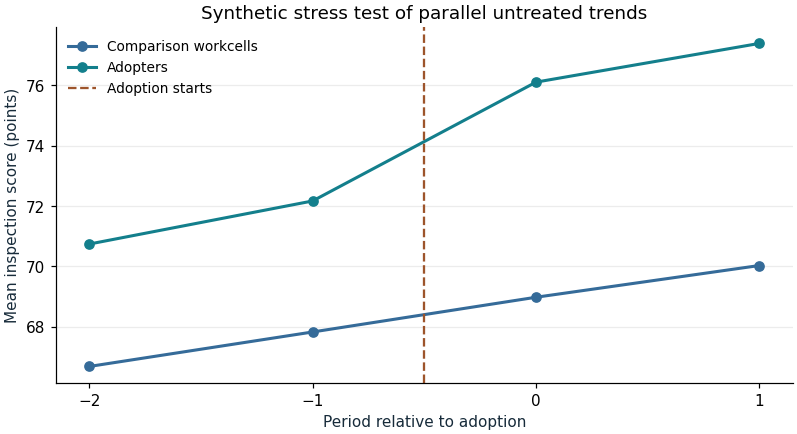

In [5]:
rng = np.random.default_rng(SEED)
n_cells = 200
mix, baseline_shock, adopt_shock = rng.standard_normal((3, n_cells))
group = (0.8 * mix + adopt_shock > 0).astype(int)
base = 70 + 3 * mix + 2 * group + 2 * baseline_shock
times = np.array([-2, -1, 0, 1])
period_shock = rng.standard_normal((n_cells, len(times)))
y_panel = (base[:, None] + 1.2 * times + TREND_BIAS * group[:, None] * times
           + TRUE_EFFECT * group[:, None] * (times >= 0) + period_shock)
panel = pd.DataFrame({
    "cell": np.repeat(np.arange(n_cells), len(times)),
    "period": np.tile(times, n_cells),
    "adopter": np.repeat(group, len(times)),
    "active": (group[:, None] * (times >= 0)).ravel(),
    "score": y_panel.ravel(),
})
print("Panel sample · one row per workcell and period")
print(panel.head().round(2).to_string(index=False))


def mean_change_difference(first, second):
    before, after = list(times).index(first), list(times).index(second)
    changes = y_panel[:, after] - y_panel[:, before]
    adopters = changes[group == 1]
    comparisons = changes[group == 0]
    estimate = adopters.mean() - comparisons.mean()
    av, cv = adopters.var(ddof=1) / len(adopters), comparisons.var(ddof=1) / len(comparisons)
    dof = (av + cv)**2 / (av**2 / (len(adopters) - 1) + cv**2 / (len(comparisons) - 1))
    margin = stats.t.ppf(0.975, dof) * np.sqrt(av + cv)
    return estimate, estimate - margin, estimate + margin


did = mean_change_difference(-1, 0)
placebo = mean_change_difference(-2, -1)
panel_means = panel.pivot_table(index="period", columns="adopter", values="score")
print("\nGroup means · score points")
print(panel_means.rename(columns={0:"Comparison", 1:"Adopters"}).round(2).to_string())
print(f"\nAdoption contrast: {did[0]:.2f} points, 95% interval [{did[1]:.2f}, {did[2]:.2f}]")
print(f"Pre-adoption placebo: {placebo[0]:.2f}, interval [{placebo[1]:.2f}, {placebo[2]:.2f}]")
print(f"Known synthetic adoption effect: {TRUE_EFFECT:.2f} points")

print(f"Absolute gap to the simulated effect: {abs(did[0] - TRUE_EFFECT):.2f} points")
fig, ax = plt.subplots(figsize=(7.25, 3.95), layout="constrained")
for group_id, name, color in [(0, "Comparison workcells", "#356B99"), (1, "Adopters", "#137F8C")]:
    ax.plot(times, panel_means[group_id], marker="o", lw=2, label=name, color=color)
ax.axvline(-0.5, linestyle="--", color="#9D542B", label="Adoption starts")
ax.set(xticks=times, xlabel="Period relative to adoption", ylabel="Mean inspection score (points)",
       title="Synthetic stress test of parallel untreated trends")
ax.grid(axis="y", alpha=.24)
ax.legend(frameon=False, fontsize=9)
plt.show()

**Economist report.** Change `TREND_BIAS` from 0.0 to 1.5 and rerun. Record the default and rerun estimates, new interval and placebo. Explain the change in the estimate given the simulator's known effect. A near-zero placebo can miss a later differential shock. Relate one of the checks to the historical case and name the extra field data you would seek.

# B · Computer scientist route

## B1 · From a causal question to a ground-truth model

**Guiding question.** Do records of robot assistance and inspection scores tell us what would happen if we set the assistance dose ourselves?

[Judea Pearl's 2011 ACM A.M. Turing Award](https://www.acm.org/binaries/content/assets/press-releases/2012/march/turing-award-11.pdf) recognized contributions to probabilistic and causal reasoning. A structural causal model represents variables with equations and arrows. The operator $\mathrm{do}(T=t)$ replaces the equation for $T$ by a set dose. This gives a different question from predicting $Y$ among naturally observed cases with $T=t$.

### Two 2026 readings

1. [Kim & Lee, *Don’t Test What You Can Deduce: Causal Discovery with Logical Inference*](https://proceedings.mlr.press/v337/kim26a.html), UAI 2026. They use logical consequences of conditional-independence information to guide discovery. In the lab, ask which statistical tests actually restrict the arrows. Our small enumerator illustrates the problem.
2. [Guo, Wu & Yiu, *The Price of Valid Inference After Causal Discovery*](https://proceedings.mlr.press/v337/guo26a.html), UAI 2026. They study uncertainty after learning a causal graph. Ask which uncertainty an interval conditional on one graph leaves out. The lab includes a separate-sample check to illustrate one design choice.

### What the simulator knows

The computer scientist sample contains 1,800 independently generated workcells at one inspection snapshot. The observed columns are baseline product mix $X$, assistance dose $T$ in standardized dose units, and inspection score $Y$ in score points. A scheduling factor $U$ can be omitted from the learner's view. Draw $X,U,\epsilon_T,\epsilon_Y$ independently from $N(0,1)$. For $h=$ `HIDDEN_STRENGTH` and $\tau=$ `TRUE_EFFECT`:

$$
 T=\frac{0.7X+hU+\epsilon_T}{\sqrt{0.7^2+h^2+1}},
 \qquad Y=70+\tau T+1.8X+2hU+2\epsilon_Y.
$$

Under an intervention, substitute $t$ into the score equation and hold $X,U,\epsilon_Y$ fixed for that workcell. The true contrast $Y_i(1)-Y_i(0)=\tau$ is 3 points at the default. One observed outcome accompanies each natural dose. The simulator supplies the structural equations and truth for checking our methods. The learner uses only the observed $X,T,Y$ columns.

At $h=0$ the ground-truth graph is $X\to T$, $X\to Y$, $T\to Y$. At $h>0$ the additional arrows are $U\to T$ and $U\to Y$.

In [6]:
def simulate_dose(h):
    rng = np.random.default_rng(SEED + 1)
    x, hidden, dose_shock, score_shock = rng.standard_normal((4, 1800))
    dose = (0.7*x + h*hidden + dose_shock) / np.sqrt(0.7**2 + h**2 + 1)
    score = 70 + TRUE_EFFECT*dose + 1.8*x + 2*h*hidden + 2*score_shock
    return pd.DataFrame({"X": x, "T": dose, "Y": score}), hidden


obs, latent = simulate_dose(HIDDEN_STRENGTH)
print(f"{len(obs):,} synthetic workcells · five observable rows")
print(obs.head().round(2).to_string(index=False))

nodes = ("X", "T", "Y")
pairs = list(itertools.combinations(nodes, 2))
truth_visible = {("X", "T"), ("X", "Y"), ("T", "Y")}
truth_dag = truth_visible | ({("U", "T"), ("U", "Y")} if HIDDEN_STRENGTH else set())

1,800 synthetic workcells · five observable rows
    X     T     Y
 1.81  1.01 78.02
-0.73  0.07 68.70
-1.09 -0.97 66.40
-0.40 -0.36 65.10
-1.15  0.03 68.05


## B2 · Discover candidate graphs and identify the effect

**Guiding question.** Which arrows follow from observed dependencies, and what additional facts orient the rest?

Our three-variable search uses marginal and partial correlations. With Gaussian variables, zero partial correlation corresponds to conditional independence. For pair $(A,B)$ and optional conditioning variable $C$, let $r_{AB\cdot C}=\operatorname{corr}(A-E[A\mid C],B-E[B\mid C])$. For the sample correlation $r$ and $k$ conditioning variables, compute

$$t=r\sqrt{\frac{n-2-k}{1-r^2}}.$$

Use a two-sided test. A p-value above $\alpha$ means the test did not detect dependence at this threshold. We use that pattern to screen graphs. A **DAG** is a directed graph without feedback loops. **D-separation** tells which paths are blocked by a conditioning set, hence which independences the graph implies.

Identification asks a second question. If $T\to Y$ is admissible and $X$ blocks $T\leftarrow X\to Y$, then under causal sufficiency, consistency, and overlap the one-unit effect is identified by backdoor adjustment:

$$ E[Y\mid\mathrm{do}(T=t)]=\int E[Y\mid T=t,X=x]\,dP(x). $$

If a compatible graph has no directed path from $T$ to $Y$, it implies a zero dose effect even if dose and score are associated through common causes. The observational tests alone can leave both stories compatible. We supply $X$ before both variables in each exercise. `TIMING="ordered"` adds an assignment record placing $T$ before this $Y$.

**Pseudocode**

1. For each pair of observed variables, test marginal independence and independence given the third variable.
2. Enumerate three-node DAGs. Compare their implied independence patterns with the tests. Apply the timing restrictions.
3. For each compatible graph, find a sufficient adjustment set for the requested effect, or record that the graph contains no directed effect.
4. Report every compatible effect description. Explain what timing, intervention record, or measured common cause would change the set.

**Python.** `NumPy`, `SciPy`, and `itertools` implement this finite search. For larger data [causal-learn](https://causal-learn.readthedocs.io/en/latest/) implements PC and FCI. PC's standard settings assume no omitted common causes. FCI represents possible latent confounding under its own assumptions. [DoWhy](https://www.pywhy.org/dowhy/main/) can express the causal query and identify an adjustment or other functional for a supplied graph. Inference also depends on acyclicity, causal Markov and faithfulness assumptions, the accuracy of the statistical tests, and whether selection and measurement are adequately represented.

Six independence tests (alpha = 0.01).
A B Given     r        p  compatible with zero
X T  None  0.57 8.3e-153                 False
X T     Y -0.16  5.2e-12                 False
X Y  None  0.74 3.6e-311                 False
X Y     T  0.59   1e-170                 False
T Y  None  0.84        0                 False
T Y     X  0.77        0                 False

Known timing: baseline. Compatible graphs: 2.
  T → Y, X → T, X → Y
  X → T, X → Y, Y → T
Directed edges common to all candidates: 2/3 true arrows.
  Candidate 1: correct skeleton edges 3/3; graph edit distance to truth 0 (reversal counts once).
  Candidate 2: correct skeleton edges 3/3; graph edit distance to truth 1 (reversal counts once).


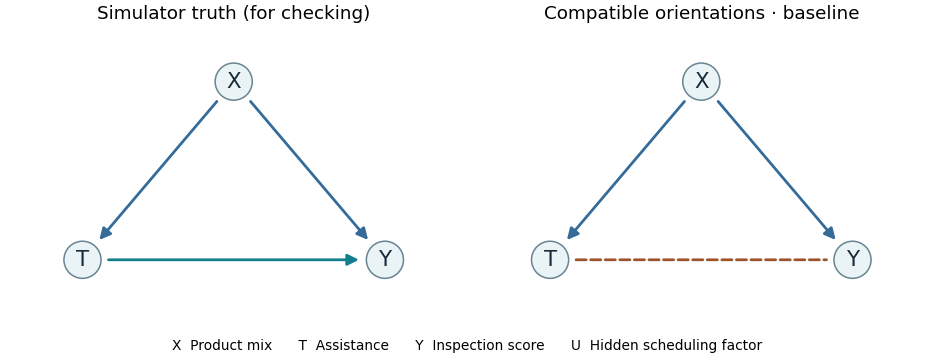

In [7]:
def independent_in_graph(edges, a, b, conditioning):
    if (a, b) in edges or (b, a) in edges:
        return False
    middle = next(node for node in nodes if node not in {a, b})
    via_middle = all((node, middle) in edges or (middle, node) in edges for node in (a, b))
    if not via_middle:
        return True
    collider = (a, middle) in edges and (b, middle) in edges
    return (conditioning != middle) if collider else (conditioning == middle)


def observed_tests(frame, alpha=0.01):
    rows = []
    correlations = frame[list(nodes)].corr()
    for a, b in pairs:
        middle = next(node for node in nodes if node not in {a, b})
        for given in (None, middle):
            r = correlations.loc[a, b]
            if given:
                ac, bc = correlations.loc[a, given], correlations.loc[b, given]
                r = (r - ac*bc) / np.sqrt((1-ac*ac)*(1-bc*bc))
            dof = len(frame) - 2 - int(given is not None)
            test = r * np.sqrt(dof / max(1 - r*r, np.finfo(float).eps))
            p_value = 2 * stats.t.sf(abs(test), dof)
            rows.append((a, b, given, r, p_value, p_value >= alpha))
    return rows


def admissible_graphs(tests, timing):
    compatible = []
    forbidden = {("T", "X"), ("Y", "X")}
    if timing == "ordered":
        forbidden.add(("Y", "T"))
    for states in itertools.product((0, 1, -1), repeat=len(pairs)):
        edges = {pair if state > 0 else pair[::-1]
                 for pair, state in zip(pairs, states) if state}
        # On three nodes a directed cycle requires each node to have an outgoing edge.
        if edges & forbidden or all(any(start == n for start, _ in edges) for n in nodes):
            continue
        if all(independent_in_graph(edges, a, b, c) == possible_zero
               for a, b, c, _, _, possible_zero in tests):
            compatible.append(edges)
    return compatible


def summarize_graph(graphs):
    if not graphs:
        return set(), set()
    edges = set.intersection(*graphs)
    skeletons = [{frozenset(edge) for edge in g} for g in graphs]
    shared = set.intersection(*skeletons)
    unresolved = shared - {frozenset(edge) for edge in edges}
    return edges, unresolved


def plot_graph(ax, directed, undirected=(), title="", label_effect=None):
    coords = {"X": (.5, .82), "T": (.17, .23), "Y": (.83, .23), "U": (.8, .82)}
    present = set(nodes) | ({"U"} if any("U" in pair for pair in directed) else set())
    for a, b in sorted(directed):
        color = "#137F8C" if (a, b) == ("T", "Y") else "#356B99"
        if a == "U":
            color = "#9D542B"
        ax.annotate("", xy=coords[b], xytext=coords[a],
                    arrowprops={"arrowstyle": "-|>", "color": color, "lw": 1.8,
                                "shrinkA": 17, "shrinkB": 17, "mutation_scale": 15})
    for pair in undirected:
        a, b = sorted(pair)
        ax.annotate("", xy=coords[b], xytext=coords[a],
                    arrowprops={"arrowstyle": "-", "color": "#9D542B", "lw": 1.8,
                                "linestyle": "--", "shrinkA": 17, "shrinkB": 17})
    for v in sorted(present):
        face = "#fff1e6" if v == "U" else "#eaf4f7"
        ax.text(*coords[v], v, ha="center", va="center", fontsize=14, color="#172B3A",
                bbox={"boxstyle": "circle,pad=0.40", "fc": face, "ec": "#698492"})
    if label_effect is not None:
        ax.text(.5, .10, label_effect, color="#137F8C", ha="center", fontsize=10)
    ax.set(xlim=(0, 1), ylim=(0, 1), title=title)
    ax.axis("off")


tests = observed_tests(obs)
graphs = admissible_graphs(tests, TIMING)
print("Six independence tests (alpha = 0.01).")
table = pd.DataFrame(tests, columns=["A", "B", "Given", "r", "p", "compatible with zero"])
print(table.to_string(index=False, formatters={"r": "{:.2f}".format, "p": "{:.2g}".format}))
print(f"\nKnown timing: {TIMING}. Compatible graphs: {len(graphs)}.")
for graph in graphs:
    print("  " + ", ".join(f"{a} → {b}" for a, b in sorted(graph)))
if not graphs:
    print("No exact match to the tested pattern. Review sampling variability, the testing threshold and the assumptions.")

shared_arrows, unresolved = summarize_graph(graphs)
if graphs and HIDDEN_STRENGTH == 0:
    real_skeleton = {frozenset(edge) for edge in truth_visible}
    print(f"Directed edges common to all candidates: {len(shared_arrows & truth_visible)}/{len(truth_visible)} true arrows.")
    for idx, graph in enumerate(graphs, 1):
        skeleton = {frozenset(edge) for edge in graph}
        directions_wrong = sum((b, a) in truth_visible for a, b in graph)
        graph_distance = len(skeleton ^ real_skeleton) + directions_wrong
        print(f"  Candidate {idx}: correct skeleton edges {len(skeleton & real_skeleton)}/3; "
              f"graph edit distance to truth {graph_distance} (reversal counts once).")

fig, (left, right) = plt.subplots(1, 2, figsize=(8.5, 3.25), layout="constrained")
plot_graph(left, truth_dag, title="Simulator truth (for checking)")
if graphs:
    plot_graph(right, shared_arrows, unresolved, title=f"Compatible orientations · {TIMING}")
else:
    right.text(.5,.5,"No compatible graph",ha="center",va="center")
    right.axis("off")
fig.supxlabel("X  Product mix      T  Assistance      Y  Inspection score      U  Hidden scheduling factor", fontsize=9)
plt.show()

**Read the diagrams.** In the default run, $X$ precedes $T$ and $Y$ and both graphs retain the same three connections. The dashed $T$–$Y$ line shows an unresolved direction. It represents alternative graphs, rather than feedback in one graph. Use the ground-truth panel only to assess the simulator. Correct connections can coexist with a reversed causal arrow. In real observations the truth graph and its edit distance are generally unavailable.

## B3 · Estimate the effect under each supported graph

**Guiding question.** Given a graph that supports adjustment for product mix, what is the average score change if we move the dose from 0 to 1?

Fit $m(t,x)=E[Y\mid T=t,X=x]$ by additive linear regression. Evaluate both assigned doses over the same observed workcells:

$$
 \widehat{\tau}(1,0)=\frac{1}{n}\sum_{i=1}^n[\widehat m(1,X_i)-\widehat m(0,X_i)].
$$

This is plug-in estimation of the adjustment formula. It equals the dose slope in our additive model. For the reverse-arrow candidate, a zero effect is a graph implication. The results table distinguishes these quantities.

**Pseudocode**

1. For a supported graph with $T\to Y$, choose the adjustment set $\{X\}$.
2. Fit a regression using dose and product mix.
3. Predict each workcell twice, setting dose to 0 and then 1. Average the paired prediction differences.
4. Resample complete workcells, refit, and compute the interval conditional on that graph. Report the alternative graph's implied effect separately.
5. Label an updated, fully oriented graph with the estimate when timing rules out the reverse direction.

**Python and metrics.** `scikit-learn` fits and evaluates the outcome model, `NumPy` supplies the pairs bootstrap, and `Matplotlib` renders the effect plot and graph. Report the estimate, a **95% bootstrap interval assuming the graph and model**, and the absolute error against simulator truth. The interval measures estimation uncertainty under one model. It does not capture uncertainty about graph direction or the adjustment set. Held-out mean absolute error (MAE) evaluates **prediction** separately and has units of score points.

In [8]:
def gcomp(frame, covariates=("X",)):
    features = frame[["T", *covariates]]
    model = LinearRegression().fit(features, frame.Y)
    return (model.predict(features.assign(T=1.0)) -
            model.predict(features.assign(T=0.0))).mean()


def slope_bootstrap(frame, reps=400):
    rng = np.random.default_rng(SEED + 31)
    t, x, y = frame[["T", "X", "Y"]].to_numpy().T
    design = np.column_stack((np.ones(len(frame)), t, x))
    slopes = np.empty(reps)
    for k in range(reps):
        sample = rng.integers(0, len(frame), size=len(frame))
        slopes[k] = np.linalg.lstsq(design[sample], y[sample], rcond=None)[0][1]
    return np.quantile(slopes, [.025, .975])


reports = []
forward_ok = any(("T", "Y") in graph for graph in graphs)
if forward_ok:
    dose_effect = gcomp(obs)
    low, high = slope_bootstrap(obs)
    reports.append(("T → Y, adjust for X", dose_effect,
                    f"[{low:.2f}, {high:.2f}]", abs(dose_effect - TRUE_EFFECT)))
if any(("T", "Y") not in graph for graph in graphs):
    reports.append(("No directed T-to-Y path", 0.0, "set by graph", abs(TRUE_EFFECT)))
if reports:
    print("Effect per unit of standardized dose under the candidate graph:")
    print(pd.DataFrame(reports, columns=["Graph case", "Effect", "Conditional 95% interval",
                                         "Absolute gap to truth"]).round(2).to_string(index=False))

train, test = train_test_split(obs, test_size=0.25, random_state=SEED)
y_hat = LinearRegression().fit(train[["T", "X"]], train.Y).predict(test[["T", "X"]])
mae = mean_absolute_error(test.Y, y_hat)
base_mae = mean_absolute_error(test.Y, np.full(len(test), train.Y.median()))
print(f"\nHeld-out prediction MAE: {mae:.2f} points; median baseline: {base_mae:.2f}")

Effect per unit of standardized dose under the candidate graph:
             Graph case  Effect Conditional 95% interval  Absolute gap to truth
    T → Y, adjust for X    2.99             [2.89, 3.11]                   0.01
No directed T-to-Y path    0.00             set by graph                   3.00

Held-out prediction MAE: 1.62 points; median baseline: 3.86


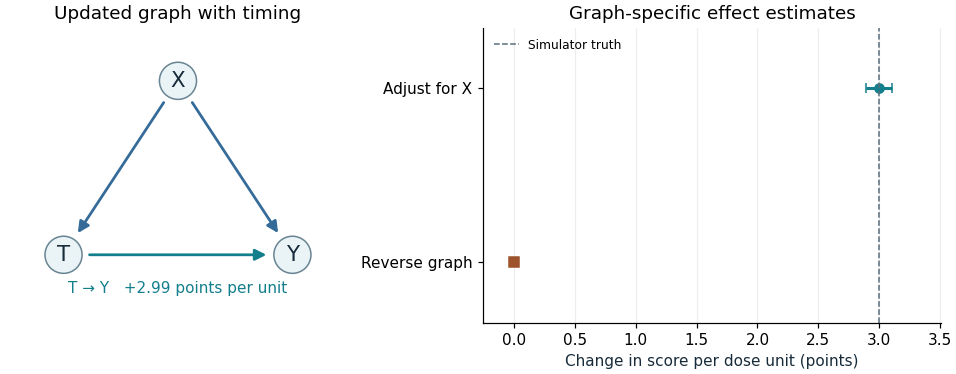

In [9]:
if forward_ok:
    fig, (left, right) = plt.subplots(1, 2, figsize=(8.7, 3.4),
                                      gridspec_kw={"width_ratios": [1, 1.32]},
                                      layout="constrained")
    example_graph = next(graph for graph in graphs if ("T", "Y") in graph)
    after_timing = admissible_graphs(tests, "ordered")
    resolved = len(after_timing) == 1 and ("T", "Y") in after_timing[0]
    plot_graph(left, after_timing[0] if resolved else example_graph,
               title=("Updated graph with timing" if resolved
                      else "One compatible graph with a dose effect"),
               label_effect=f"T → Y   {dose_effect:+.2f} points per unit")
    right.hlines(1, low, high, color="#137F8C", lw=2)
    right.plot([low, high], [1, 1], linestyle="none", marker="|", color="#137F8C")
    right.plot(dose_effect, 1, marker="o", color="#137F8C")
    reverse_ok = any(("T", "Y") not in graph for graph in graphs)
    if reverse_ok:
        right.plot(0, 0, marker="s", color="#9D542B")
    right.axvline(TRUE_EFFECT, color="#586D7C", ls="--", lw=1, label="Simulator truth")
    right.set(ylim=((-0.35,1.35) if reverse_ok else (0.6,1.35)),
              yticks=([0,1] if reverse_ok else [1]),
              yticklabels=(["Reverse graph","Adjust for X"] if reverse_ok else ["Adjust for X"]),
              xlabel="Change in score per dose unit (points)", title="Graph-specific effect estimates")
    if reverse_ok:
        right.set_xlim(-.25, max(high, TRUE_EFFECT)+.4)
    right.legend(loc="best", fontsize=8, frameon=False)
    right.grid(axis="x", alpha=.22)
    plt.show()

## B4 · Interpret and test what could change the conclusion

**Guiding question.** Which result moves when we change our evidence about the graph, and which result moves when we change the data-generating process?

In the saved default run, the forward graph gives about +2.99 points per dose unit with a conditional interval of [2.89, 3.11]. The reverse graph gives 0. The left plot shows the forward graph that remains when an assignment record fixes the order. The range of answers across graphs is a separate source of uncertainty from the interval around one estimate.

- **Timing.** Set `TIMING="ordered"`. The graph and effect table should lose the reverse-arrow candidate. The held-out predictions use the same records and model. An assignment timestamp can establish order for this outcome. It leaves open whether a third factor influences both dose and score.
- **Test sensitivity and sample split.** Compare candidate counts at several test thresholds. Discover on one random half, then estimate with the other. This check separates the rows used in discovery from those used to fit an effect. The second half still requires a credible graph and adequate overlap.
- **Omitted causes.** Keep measured strict timing and simulate `HIDDEN_STRENGTH=0.9`. Compare the slope adjusting for $X$ with a simulator-only check that also adjusts for $U$. In the saved check, the estimate using only X rises to about +4.37 points even though the effect in the simulator is +3.00. This shows why a timing record can settle direction while leaving confounding unresolved.

In [10]:
threshold_rows = []
for level in (0.001, 0.01, 0.05):
    possible = admissible_graphs(observed_tests(obs, alpha=level), TIMING)
    threshold_rows.append((level, len(possible)))
print(pd.DataFrame(threshold_rows, columns=["Test alpha", "Number of compatible graphs"]).to_string(index=False))

discovery, estimation = train_test_split(obs, test_size=0.5, random_state=SEED + 41)
split_graphs = admissible_graphs(observed_tests(discovery), TIMING)
print(f"\nSplit-sample check: {len(split_graphs)} candidate graph(s) from {len(discovery)} discovery rows.")
if any(("T","Y") in graph for graph in split_graphs):
    print(f"Adjusted effect on {len(estimation)} separate rows: {gcomp(estimation):+.2f} points per dose unit.")
else:
    print("Discovery half gives no compatible forward graph under these settings.")

stressed, scheduling = simulate_dose(0.9)
print(f"\nOmitted-cause scenario (h=0.9): adjusting for X alone gives {gcomp(stressed):+.2f} points.")
print(f"Simulator-only check with X and U gives {gcomp(stressed.assign(U=scheduling), ('X','U')):+.2f} points.")
print(f"The simulator's true effect is {TRUE_EFFECT:+.2f} points per unit.")

 Test alpha  Number of compatible graphs
      0.001                            2
      0.010                            2
      0.050                            2

Split-sample check: 2 candidate graph(s) from 900 discovery rows.
Adjusted effect on 900 separate rows: +2.93 points per dose unit.

Omitted-cause scenario (h=0.9): adjusting for X alone gives +4.37 points.
Simulator-only check with X and U gives +2.99 points.
The simulator's true effect is +3.00 points per unit.


**Computer scientist report.** Compare graph counts, graph-implied effects, the conditional interval when available, and held-out MAE between the default and `TIMING="ordered"`. Use one figure or table. Explain what the time record adds and which scheduling or product-mix variable you would measure in a field study.

**What remains open?** The known truth and iid Gaussian equations are features of this simulation. A real deployment may have feedback, time-varying selection or measurement error. Explore overlap, alternative conditional-independence tests, graph ambiguity and omitted-variable sensitivity. Where possible, use randomized or staggered dose changes, verified assignment records, or a discovery sample separate from an intervention or estimation sample. Greater predictive accuracy alone leaves these causal questions open.

# Share and compare the two approaches

In a **two-minute report**, state the research question, treatment or dose, outcome and units. Show one result and describe the assumption your rerun probes. Explain one piece of evidence you could collect for your own topic.

- **Economists.** Show the group comparison in the historical survey. Use the synthetic panel to show how a differential trend changes the DiD estimate, interval and placebo.
- **Computer scientists.** Show the graph before and after adding timing. Explain how the adjustment estimate and its interval relate to one graph. Name a possible omitted common cause and explain why the prediction metric does not resolve it.

**Individual Ed reply.** *Question and treatment / changed setting / result with units / assumption and check / next evidence for my own study*. If you share a Colab copy, check that the instructor can view it. Keep the survey findings and simulation outputs labeled.

## Source notes

### Economist route

- Card, D., & Krueger, A. B. (1994). *Minimum Wages and Employment: A Case Study of the Fast-Food Industry in New Jersey and Pennsylvania*. American Economic Review, 84(4), 772–793. [Article and Table 3](https://eml.berkeley.edu/~card/papers/njmin-aer.pdf) · [Authors' public data archive](https://davidcard.berkeley.edu/data_sets/njmin.zip).
- Baker, A., Callaway, B., Cunningham, S., Goodman-Bacon, A., & Sant'Anna, P. H. C. (2026). *Difference-in-Differences Designs: A Practitioner's Guide*. Journal of Economic Literature, 64(2), 498–557. [DOI](https://doi.org/10.1257/jel.20251650).
- Wiltshire, J. C., McPherson, C., Reich, M., & Sosinskiy, D. (2026). *Minimum Wage Effects and Monopsony Explanations*. Journal of Labor Economics, 44(4). [DOI](https://doi.org/10.1086/735551).

### Computer scientist route

- Pearl, J. (2009). *Causal inference in statistics: An overview*. Statistics Surveys, 3, 96–146. [DOI](https://doi.org/10.1214/09-SS057).
- Kim, J., & Lee, S. (2026). *Don’t Test What You Can Deduce: Causal Discovery with Logical Inference*. UAI, Proceedings of Machine Learning Research, 337, 2958–2993. [Proceedings](https://proceedings.mlr.press/v337/kim26a.html).
- Guo, D., Wu, J., & Yiu, S. M. (2026). *The Price of Valid Inference After Causal Discovery*. UAI, Proceedings of Machine Learning Research, 337, 1804–1822. [Proceedings](https://proceedings.mlr.press/v337/guo26a.html).